# Anomaly Detection with a VAE — a beginner's notebook

### The idea, in plain words

Imagine you hire someone to watch a machine every day for a year. They see only *normal* days. After a year, they know normal so well that anything odd jumps out at them immediately — even if they can't explain why.

That's what we're building.

1. We show a neural network **only normal data** and ask it to learn to copy it.
2. It gets very good at copying normal data.
3. When we show it something weird, it copies it **badly** — because it has never seen anything like it.
4. **Bad copy = anomaly.**

That's the whole trick. Everything below is just details.

### What's a VAE?

An **autoencoder** is a network shaped like an hourglass:

```
input (2 numbers)  ->  SQUEEZE  ->  tiny code (1 number)  ->  EXPAND  ->  output (2 numbers)
      encoder                                                  decoder
```

We train it so the output matches the input. The squeeze in the middle is the point: the network can't just memorise, it must learn the *pattern*.

A **Variational** autoencoder adds one twist: instead of squeezing to a single number, it squeezes to a **mean and a spread** — a small cloud of possible codes rather than one point. This makes the model better behaved and gives us a cleaner way to say "how surprising is this?"

You don't need to fully understand the twist to use it. Run the notebook, then come back.

---

## Step 1 — Imports

If anything is missing: `pip install torch numpy matplotlib`

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

print("Ready. torch version:", torch.__version__)

Ready. torch version: 2.10.0+cu128


## Step 2 — Make some data

We'll use a machine with just **2 sensors**, so we can draw everything on a simple scatter plot and actually *see* what's going on.

- `temperature`
- `vibration`

On a normal day these two are linked: when the machine runs hotter, it vibrates more, following a curve. The normal points form a **band**.

An anomaly is a point that falls **off that band**.

In [2]:
def make_normal(n):
    # Normal days: temperature varies, and vibration follows from it.
    temperature = np.random.normal(70, 6, n)
    vibration = 0.5 + 0.0015 * (temperature - 55) ** 2
    vibration = vibration + np.random.normal(0, 0.08, n)   # a little sensor noise
    return np.column_stack([temperature, vibration])


def make_anomalies(n):
    # Broken days: readings land somewhere in the normal RANGE,
    # but not on the normal CURVE.
    points = []
    while len(points) < n:
        temperature = np.random.uniform(57, 85)
        vibration = np.random.uniform(0.2, 2.85)
        on_curve = 0.5 + 0.0015 * (temperature - 55) ** 2
        # skip it if it happens to land on the curve - that would just be a
        # normal day, and it would be unfair to label it an anomaly.
        if abs(vibration - on_curve) > 0.35:
            points.append([temperature, vibration])
    return np.array(points)


train_data = make_normal(3000)      # the VAE only ever sees this

test_normal = make_normal(600)
test_anomaly = make_anomalies(100)

test_data = np.vstack([test_normal, test_anomaly])
# labels: 0 = normal, 1 = anomaly. Only used at the very end, to check our work.
test_labels = np.array([0] * 600 + [1] * 100)

print("training data:", train_data.shape)
print("test data:    ", test_data.shape)

training data: (3000, 2)
test data:     (700, 2)


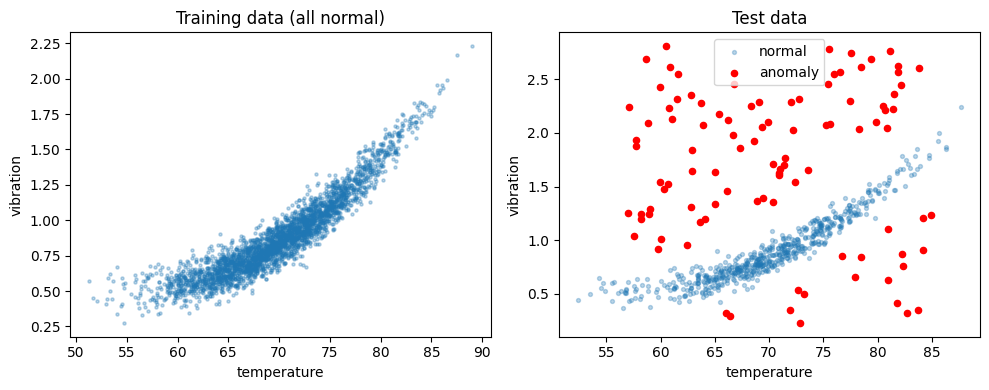

In [3]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(train_data[:, 0], train_data[:, 1], s=5, alpha=0.3)
plt.xlabel("temperature"); plt.ylabel("vibration")
plt.title("Training data (all normal)")

plt.subplot(1, 2, 2)
plt.scatter(test_normal[:, 0], test_normal[:, 1], s=8, alpha=0.3, label="normal")
plt.scatter(test_anomaly[:, 0], test_anomaly[:, 1], s=20, c="red", label="anomaly")
plt.xlabel("temperature"); plt.ylabel("vibration")
plt.title("Test data"); plt.legend()

plt.tight_layout(); plt.show()

Look at the red points. Many of them have a perfectly ordinary temperature **and** a perfectly ordinary vibration — they'd pass any simple "is this reading too high?" check.

What's wrong is the **combination**. That's what we need the model to learn.

## Step 3 — Put both sensors on the same scale

Temperature is around 70. Vibration is around 1. If we leave them like that, the network will obsess over temperature and ignore vibration entirely, just because the numbers are bigger.

So we rescale both to be roughly centred at 0 with a spread of 1.

**Important:** we compute the mean and spread from the **training data only**, then apply those same numbers to the test data. Never peek at the test set.

In [4]:
mean = train_data.mean(axis=0)
std = train_data.std(axis=0)

def rescale(data):
    return (data - mean) / std

X_train = torch.tensor(rescale(train_data), dtype=torch.float32)
X_test = torch.tensor(rescale(test_data), dtype=torch.float32)

print("before:", train_data.mean(axis=0).round(2))
print("after: ", X_train.mean(axis=0).numpy().round(2))

before: [69.83  0.88]
after:  [ 0. -0.]


## Step 4 — Build the VAE

Read the code below as three pieces:

**Encoder** — takes the 2 sensor readings, and outputs two things:
- `mu` — the centre of the code
- `logvar` — how spread out the code is

(We output `logvar` instead of the spread directly, only because a network can output any number, positive or negative, and this way we never accidentally get a negative spread.)

**The sampling step** — pick a random point from that little cloud:

```
code = mu + spread * (random noise)
```

Writing it this way — instead of "draw a random sample" — is what lets training work. The randomness sits in a separate piece that has nothing to learn, so the learning signal can still flow back through `mu` and `spread`.

**Decoder** — takes the code and rebuilds the 2 sensor readings.

In [5]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()

        # ENCODER: 2 numbers in -> 16 hidden
        self.encoder = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
        )
        self.to_mu = nn.Linear(16, 1)        # centre of the code
        self.to_logvar = nn.Linear(16, 1)    # spread of the code

        # DECODER: 1 code number -> back to 2 numbers
        self.decoder = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 2),
        )

    def forward(self, x):
        h = self.encoder(x)
        mu = self.to_mu(h)
        logvar = self.to_logvar(h)

        # sample a code from the little cloud
        spread = torch.exp(0.5 * logvar)
        noise = torch.randn_like(spread)
        code = mu + spread * noise

        rebuilt = self.decoder(code)
        return rebuilt, mu, logvar


model = VAE()
print(model)

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
  )
  (to_mu): Linear(in_features=16, out_features=1, bias=True)
  (to_logvar): Linear(in_features=16, out_features=1, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=2, bias=True)
  )
)


## Step 5 — The loss (what "doing well" means)

Two things to score, added together.

**1. Rebuild error.** How far is the output from the input? Just squared difference. Small is good.

**2. KL term.** A gentle nudge that keeps all the little code-clouds packed near zero instead of drifting apart. Without it the model would cheat: it would spread codes far apart and just memorise each point, learning no pattern at all.

The formula looks scary but it's one line, and you can use it without deriving it:

$$\text{KL} = -\tfrac{1}{2}\sum \left(1 + \text{logvar} - \text{mu}^2 - e^{\text{logvar}}\right)$$

All you need to know: this number is **0 when the cloud sits exactly at the centre with spread 1**, and grows as it drifts away.

In [6]:
def loss_function(x, rebuilt, mu, logvar):
    # 1. how badly did we rebuild the input?
    rebuild_error = ((x - rebuilt) ** 2).sum(dim=1)

    # 2. how far did the code-cloud drift?
    kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)

    # total, averaged over the batch
    return (rebuild_error + kl).mean(), rebuild_error.mean().item(), kl.mean().item()

## Step 6 — Train it

Standard PyTorch loop. For each batch:

1. run the data through the model
2. compute the loss
3. `zero_grad()` — clear old gradients
4. `backward()` — work out which way each weight should move
5. `step()` — move them

Repeat 200 times over the whole dataset. Takes a few seconds on a laptop.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

EPOCHS = 200
BATCH_SIZE = 128

history = []

for epoch in range(EPOCHS):
    # shuffle the data each time round
    shuffled = X_train[torch.randperm(len(X_train))]
    epoch_loss = 0.0

    for i in range(0, len(shuffled), BATCH_SIZE):
        batch = shuffled[i:i + BATCH_SIZE]

        rebuilt, mu, logvar = model(batch)
        loss, rebuild_err, kl = loss_function(batch, rebuilt, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(batch)

    epoch_loss /= len(shuffled)
    history.append(epoch_loss)

    if (epoch + 1) % 40 == 0:
        print(f"epoch {epoch+1:3d}  loss {epoch_loss:.4f}   "
              f"(rebuild {rebuild_err:.4f}, KL {kl:.4f})")

epoch  40  loss 1.2489   (rebuild 0.7170, KL 0.6685)
epoch  80  loss 1.2453   (rebuild 0.4733, KL 0.7783)
epoch 120  loss 1.2315   (rebuild 0.5920, KL 0.5794)
epoch 160  loss 1.2399   (rebuild 0.4866, KL 0.5682)
epoch 200  loss 1.2319   (rebuild 0.6562, KL 1.0190)


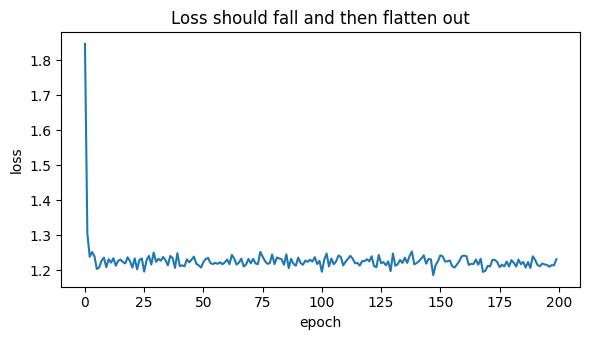

In [8]:
plt.figure(figsize=(6, 3.5))
plt.plot(history)
plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Loss should fall and then flatten out")
plt.tight_layout(); plt.show()

## Step 7 — Did it learn the pattern?

Before scoring anything, let's just look. We feed the training data in and plot what comes back out.

If the model learned the band, the rebuilt points should trace the same curve.

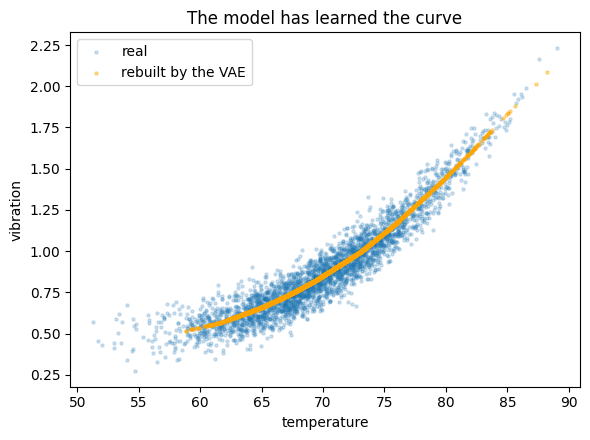

In [9]:
model.eval()
with torch.no_grad():
    h = model.encoder(X_train)
    code = model.to_mu(h)                # use the centre, no randomness
    rebuilt = model.decoder(code)

# undo the rescaling so we can plot in the original units
rebuilt_original = rebuilt.numpy() * std + mean

plt.figure(figsize=(6, 4.5))
plt.scatter(train_data[:, 0], train_data[:, 1], s=5, alpha=0.2, label="real")
plt.scatter(rebuilt_original[:, 0], rebuilt_original[:, 1], s=5, alpha=0.4,
            c="orange", label="rebuilt by the VAE")
plt.xlabel("temperature"); plt.ylabel("vibration")
plt.title("The model has learned the curve")
plt.legend(); plt.tight_layout(); plt.show()

## Step 8 — Score every point

Now the payoff. For each test point:

1. squeeze it to a code
2. rebuild it
3. measure how far the rebuild landed from the original

**Big distance = the model couldn't rebuild it = anomaly.**

In [10]:
def anomaly_score(data_tensor):
    model.eval()
    with torch.no_grad():
        h = model.encoder(data_tensor)
        code = model.to_mu(h)
        rebuilt = model.decoder(code)
        return ((data_tensor - rebuilt) ** 2).sum(dim=1).numpy()


train_scores = anomaly_score(X_train)
test_scores = anomaly_score(X_test)

print("average score on normal training data:", train_scores.mean().round(4))
print("average score on test normals:        ", test_scores[test_labels == 0].mean().round(4))
print("average score on test anomalies:      ", test_scores[test_labels == 1].mean().round(4))

average score on normal training data: 0.1181
average score on test normals:         0.1264
average score on test anomalies:       8.0068


## Step 9 — Where to draw the line

We have scores. Now: how high is *too* high?

Simple, practical rule — take the score that 99% of our **normal training data** falls below. Anything above that is flagged.

Why this works: we're saying "accept a 1% false alarm rate on normal data." We never needed to look at a single anomaly to make that decision, which matters, because in the real world you usually don't have labelled anomalies to tune with.

Want fewer false alarms? Use 99.5. Want to catch more anomalies and tolerate more noise? Use 95.

In [11]:
threshold = np.percentile(train_scores, 99)
predictions = (test_scores > threshold).astype(int)

print(f"threshold = {threshold:.4f}\n")

# count the four outcomes
correct_normal = ((predictions == 0) & (test_labels == 0)).sum()
false_alarm    = ((predictions == 1) & (test_labels == 0)).sum()
missed         = ((predictions == 0) & (test_labels == 1)).sum()
caught         = ((predictions == 1) & (test_labels == 1)).sum()

print(f"normal, correctly ignored : {correct_normal}")
print(f"normal, false alarm       : {false_alarm}")
print(f"anomaly, MISSED           : {missed}")
print(f"anomaly, caught           : {caught}")

print(f"\ncaught {caught}/{caught+missed} anomalies "
      f"({100*caught/(caught+missed):.0f}%)")
print(f"false alarm rate: {100*false_alarm/(correct_normal+false_alarm):.1f}%")

threshold = 0.8544

normal, correctly ignored : 590
normal, false alarm       : 10
anomaly, MISSED           : 2
anomaly, caught           : 98

caught 98/100 anomalies (98%)
false alarm rate: 1.7%


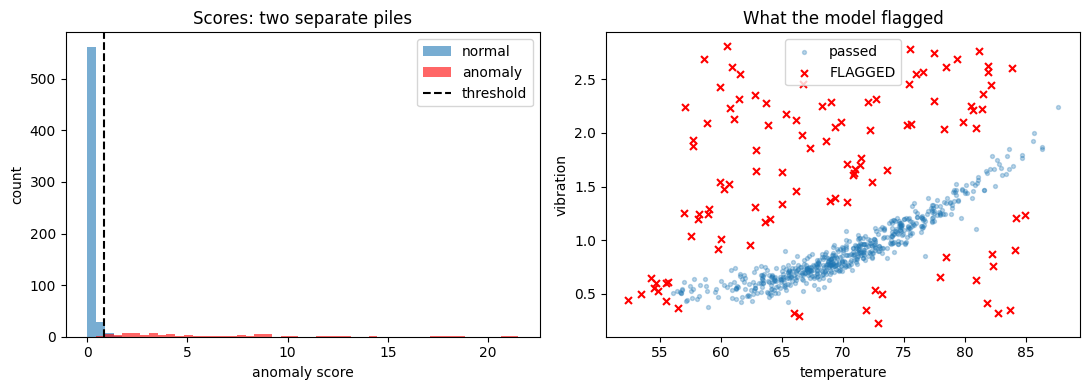

In [12]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
bins = np.linspace(0, np.percentile(test_scores, 99), 50)
plt.hist(test_scores[test_labels == 0], bins=bins, alpha=0.6, label="normal")
plt.hist(test_scores[test_labels == 1], bins=bins, alpha=0.6, label="anomaly", color="red")
plt.axvline(threshold, color="black", linestyle="--", label="threshold")
plt.xlabel("anomaly score"); plt.ylabel("count")
plt.title("Scores: two separate piles"); plt.legend()

plt.subplot(1, 2, 2)
flagged = predictions == 1
plt.scatter(test_data[~flagged, 0], test_data[~flagged, 1],
            s=8, alpha=0.3, label="passed")
plt.scatter(test_data[flagged, 0], test_data[flagged, 1],
            s=25, c="red", marker="x", label="FLAGGED")
plt.xlabel("temperature"); plt.ylabel("vibration")
plt.title("What the model flagged"); plt.legend()

plt.tight_layout(); plt.show()

The right-hand plot is the one to study. The model drew an invisible boundary around the normal band, entirely on its own, without ever being told what an anomaly looks like.

Points sitting *on* the band pass. Points off it get flagged — even where their temperature and vibration are individually unremarkable.

## Step 10 — Try it on a single reading

This is what using the model in production actually looks like.

In [13]:
def check_reading(temperature, vibration):
    point = np.array([[temperature, vibration]])
    x = torch.tensor((point - mean) / std, dtype=torch.float32)
    score = anomaly_score(x)[0]
    verdict = "ANOMALY" if score > threshold else "normal"
    print(f"temp={temperature:5.1f}  vib={vibration:4.2f}  ->  "
          f"score {score:7.4f}  ->  {verdict}")


check_reading(70, 0.84)   # sits on the curve        -> normal
check_reading(80, 1.44)   # sits on the curve, hotter -> normal
check_reading(70, 2.10)   # normal temp, but vibrating far too much for it
check_reading(84, 0.55)   # very hot yet barely vibrating - impossible

temp= 70.0  vib=0.84  ->  score  0.0040  ->  normal
temp= 80.0  vib=1.44  ->  score  0.0615  ->  normal
temp= 70.0  vib=2.10  ->  score  8.4619  ->  ANOMALY
temp= 84.0  vib=0.55  ->  score  6.1260  ->  ANOMALY


## Step 11 — Making it yours

### Use your own data

Replace Step 2 with your own numbers. Two changes needed:

```python
train_data = your_normal_data          # a numpy array, shape (rows, columns)
```

and in the model, swap every `2` for your number of columns:

```python
nn.Linear(n_features, 16)   # in the encoder
nn.Linear(16, n_features)   # last line of the decoder
```

Everything else stays the same.

### Knobs to turn

| Knob | What happens |
|---|---|
| the `1` in `to_mu` / `Linear(1, 16)` (code size) | Bigger = the model can copy more detail, including anomalies. Then it stops flagging them. Start small. |
| `16` (hidden size) | Bigger = more powerful model. Same warning as above. |
| `EPOCHS` | Too few = it hasn't learned yet. Watch the loss curve flatten. |
| `99` in the threshold | Directly controls your false alarm rate. |

### The one big trap

**A model that's too powerful stops working.** It becomes so good at copying that it copies anomalies well too, and then nothing gets flagged. If your results look bad, try making the model *smaller* before you try making it bigger. This surprises everyone the first time.

### Things to try right now

1. Change the code size from `1` to `2` in both places and re-run. Does it get better or worse?
2. Change `EPOCHS` to `20`. Look at the loss curve — has it flattened?
3. Add anomalies into `train_data` and see how much damage it does.

### When you're ready for more

The score we used is just rebuild error, which is the beginner-friendly version. A VAE can also give you a proper probability — "how likely is this reading?" — by combining the rebuild error with the KL term. That's the ELBO, and it's the natural next step once this notebook makes sense.